In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Demostración: K-Means clustering

Nota: Ejemplo adaptado de "Hands on Machine Learning" de Geron Aurelien.

In [2]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

Creemos un data set sintético para demostrar el algoritmo de K-Means usando la función make_blobs de Scikit-Learn.

(2000, 2)


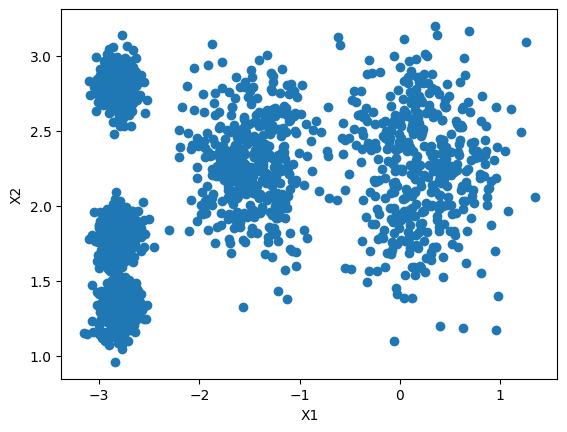

In [3]:
# Los centros de nuestros grupos, k=5
blob_centers = np.array([
    [ 0.2,  2.3],
    [-1.5 ,  2.3],
    [-2.8,  1.8],
    [-2.8,  2.8],
    [-2.8,  1.3]
])

# El "tamaño" de cada grupo (desviación estándar)
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

X, y = make_blobs(
    n_samples=2000,
    centers=blob_centers,
    cluster_std=blob_std,
    random_state=7
)

print(X.shape)
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel('X1')
plt.ylabel('X2');

Ahora, creamos una instancia de la clase, sabemos que queremos 5 grupos, aunque no siempre estaremos seguros.

In [4]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=1, n_init='auto')
kmeans.fit(X)

y_pred = kmeans.predict(X)
# Esta información también se encuentra en KMeans().labels_
# ¿Para qué más podemos usar predict entonces?
y_pred

array([1, 4, 0, ..., 3, 0, 4], shape=(2000,), dtype=int32)

Los centroides estan almacenados en:

In [5]:
centroids = kmeans.cluster_centers_
centroids

array([[ 0.20876306,  2.25551336],
       [-2.80037642,  1.30082566],
       [-1.46679593,  2.28585348],
       [-2.79290307,  2.79641063],
       [-2.80389616,  1.80117999]])

Miremos la asignación de grupos.

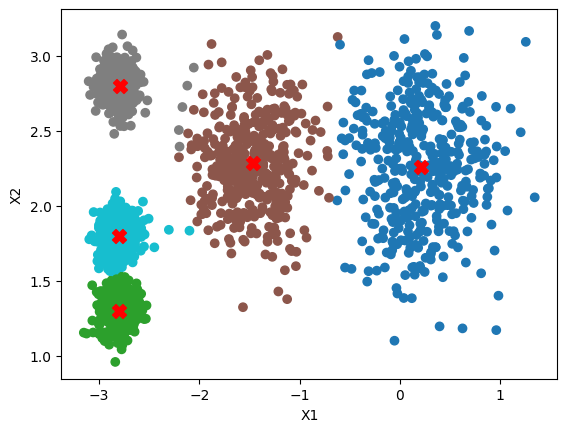

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10')
plt.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');

Podemos predecir el grupo de nuevas observaciones. Ojo, no se recalculan los centroides.

In [7]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([0, 0, 3, 3], dtype=int32)

La distancia a los centroides se puede obtener con el método `transform`. Esto es similar a un "soft clustering".

In [8]:
kmeans.transform(X_new).round(2)

array([[0.33, 2.89, 1.49, 2.9 , 2.81],
       [2.8 , 5.84, 4.48, 5.85, 5.81],
       [3.29, 1.71, 1.69, 0.29, 1.21],
       [3.22, 1.22, 1.55, 0.36, 0.73]])

Recordemos que durante la presentación discutimos acerca de la inicialización del algoritmo y como una mala inicialización puede llevar a un resultado subóptimo. En Scikit-Learn podemos controlar este comportamiento con los parámetros `n_init` y `init`.
Con inicialización aleatoria es necesario repetir varias veces el algoritmo para encontrar una buena partición.

K-means++ es una forma de inicializar el algoritmo K-means de una manera más inteligente, para mantener los puntos de inicialización alejados entre sí.
Para realizar la inicialización, primero elige un centroide inicial al azar entre las observaciones en 𝑋. Luego, para los centroides restantes, elige el siguiente centroide entre los puntos restantes en 𝑋 con probabilidad proporcional a la distancia al cuadrado desde el centroide más cercano.

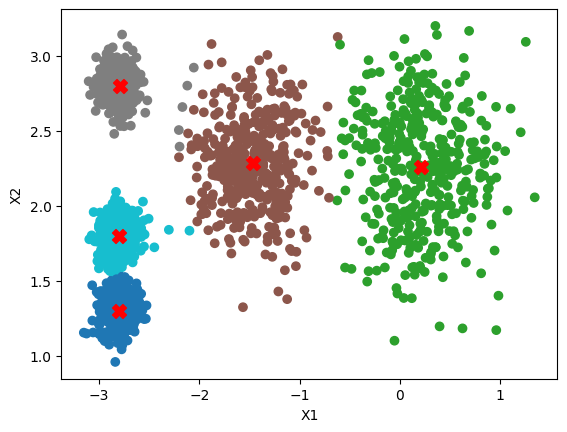

In [9]:
# Probemos la inicialización k-means++ con 100 arranques
kmeans = KMeans(n_clusters=k, init='k-means++', n_init=100, random_state=42)
y_pred = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10')
plt.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');

También es posible especificar la posición inicial de los centroides con `init` como arreglo; un ejemplo está al final del notebook.

Para seleccionar el mejor modelo, necesitaremos una forma de evaluar su rendimiento. Desafortunadamente, la agrupación es una tarea no supervisada, por lo que no tenemos las etiquetas. Pero podemos medir la distancia entre cada instancia y su centroide. A la suma de las distancias cuadradas a su centroide asignado se le llama inercia. De hecho, cuando ejecutamos KMeans con diferentes inicializaciones, el algoritmo elige la de menor inercia.

La inercia siempre disminuye con el número de grupos (k), pero podemos evaluar su tasa de cambio para encontrar el punto de inflexión. Esto es lo que vimos como el método del codo.

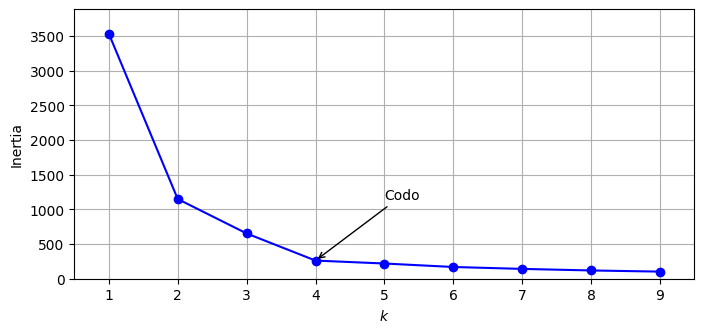

In [10]:
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, init='k-means++', random_state=42).fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("Codo", xy=(4, inertias[3]), xytext=(5, inertias[3] + 0.25 * max(inertias)),
             arrowprops=dict(arrowstyle="->"))
plt.xlim(0.5, 9.5)
plt.ylim(0, 1.1 * max(inertias))
plt.grid();

Parece que 4 grupos es una buena opción, aunque combina los grupos más pequeños.

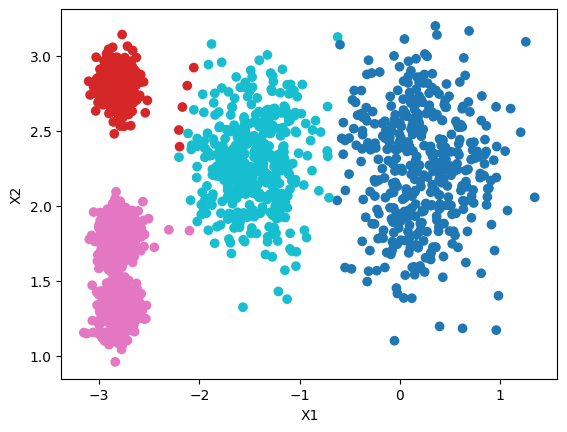

In [11]:
plt.scatter(X[:, 0], X[:, 1], c=kmeans_per_k[3].labels_, cmap='tab10')
plt.xlabel('X1')
plt.ylabel('X2');

Otro enfoque es observar la puntuación de silueta, que es el coeficiente de silueta medio sobre todas las observaciones. El coeficiente de silueta de una instancia es igual a $(b - a) / \max(a, b)$ donde $a$ es la distancia media a las otras instancias del mismo grupo y $b$ es la distancia media a las instancias del siguiente clúster más cercano (definido como el que minimiza $b$, excluyendo el propio clúster de la instancia). 

El coeficiente de silueta puede variar entre -1 y +1: un coeficiente cercano a +1 significa que la instancia está dentro de su propio grupo y lejos de otros grupos, mientras que un coeficiente cercano a 0 significa que está cerca del límite de un grupo. Y finalmente un coeficiente cercano a -1 significa que es posible que la instancia haya sido asignada al clúster incorrecto.

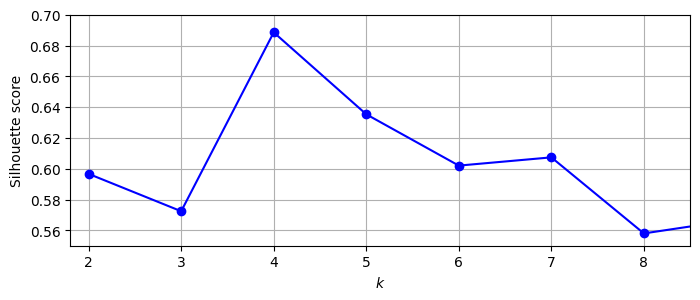

In [13]:
silhouette_scores = [
    silhouette_score(X, model.labels_)
    for model in kmeans_per_k[1:]
]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.grid();

Como se puede ver, esta visualización es mucho más rica que la anterior: en particular, aunque confirma que $k=4$ es una muy buena elección, también subraya el hecho de que $k=5$ también es bastante buena.

Se obtiene una visualización aún más informativa cuando se traza el coeficiente de silueta de cada instancia, ordenado por el grupo al que están asignados y por el valor del coeficiente. Esto se llama diagrama de silueta:

In [14]:
from sklearn.metrics import silhouette_samples

def grafica_silueta(modelo, X, ax):
    """Diagrama de silueta: una barra por instancia, agrupada por cluster."""
    etiquetas = modelo.labels_
    valores = silhouette_samples(X, etiquetas)
    promedio = silhouette_score(X, etiquetas)

    y_inf = 10
    for c in np.unique(etiquetas):
        vals = np.sort(valores[etiquetas == c])
        y_sup = y_inf + len(vals)
        ax.fill_betweenx(np.arange(y_inf, y_sup), 0, vals, alpha=0.7)
        ax.text(-0.05, y_inf + 0.5 * len(vals), str(c))
        y_inf = y_sup + 10

    ax.axvline(promedio, color="red", linestyle="--", label=f"Promedio = {promedio:.2f}")
    ax.set_title(f"k = {modelo.n_clusters}")
    ax.set_xlabel("Coeficiente de silueta")
    ax.set_yticks([])
    ax.legend(loc="lower right")

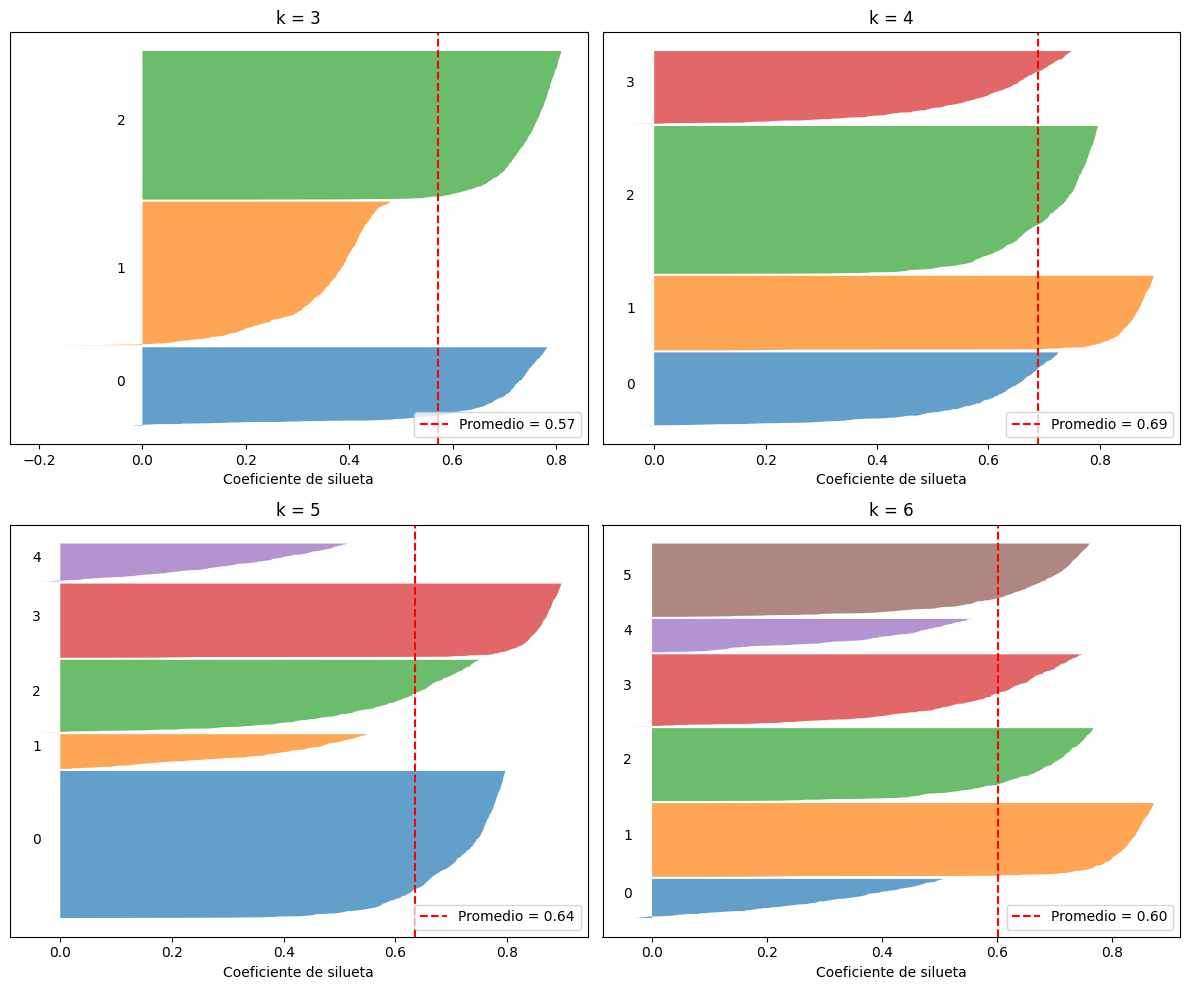

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for modelo, ax in zip(kmeans_per_k[2:6], axes.ravel()):
    grafica_silueta(modelo, X, ax)
plt.tight_layout()
plt.show()

Con este diagrama, **k=4** es el único valor en el que todos los grupos superan el promedio de la silueta (línea roja). Con **k=5**, que es el número real de grupos en estos datos, dos grupos quedan por debajo de la línea. Así que la silueta sugiere k=4 y el conocimiento de los datos sugiere k=5: conviene mirar ambas cosas.

Sin embargo, K-Means asume grupos esféricos, e intenta encontrar este tipo de grupos. Veamos que pasa si esta suposición no es correcta.

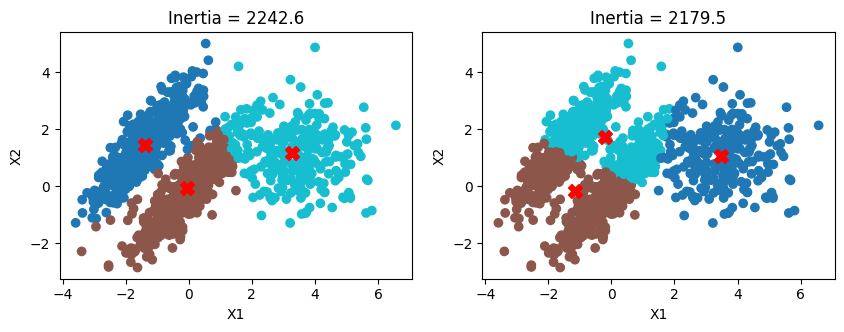

In [15]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

kmeans_good = KMeans(n_clusters=3,
                     init=np.array([[-1.5, 2.5], [0.5, 0], [4, 0]]),
                     n_init=1, random_state=42)
kmeans_bad = KMeans(n_clusters=3, random_state=42, n_init=100, init='k-means++')

kmeans_good.fit(X)
kmeans_bad.fit(X)

plt.figure(figsize=(10, 3.2))

plt.subplot(121)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_good.labels_, cmap='tab10')
plt.scatter(kmeans_good.cluster_centers_[:, 0], kmeans_good.cluster_centers_[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');
plt.title(f"Inertia = {kmeans_good.inertia_:.1f}")

plt.subplot(122)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_bad.labels_, cmap='tab10')
plt.scatter(kmeans_bad.cluster_centers_[:, 0], kmeans_bad.cluster_centers_[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');
plt.title(f"Inertia = {kmeans_bad.inertia_:.1f}");

**Lectura:** compara la inercia de ambas soluciones (título de cada gráfica). La solución con menor inercia no siempre es la que mejor refleja los grupos reales: K-Means asume grupos esféricos y aquí la nube de puntos es alargada, así que el resultado depende de cómo se ubiquen los centroides iniciales.

# DBSCAN: agrupamiento basado en densidad

K-Means necesita que definamos $k$ y representa cada cluster mediante un centroide. **DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) utiliza la densidad local: identifica regiones con suficientes observaciones cercanas, separadas por regiones menos densas. Puede encontrar clusters irregulares y **marcar observaciones como ruido** (`-1`). No necesitamos elegir el número de clusters de antemano.

Los dos hiperparámetros principales son:

- `eps`: distancia máxima para considerar a dos observaciones vecinas, **en las unidades de la métrica elegida**.
- `min_samples`: número mínimo de observaciones en el vecindario de radio `eps` (incluida la observación misma) para que un punto sea **central** (*core point*).

Un **punto frontera** puede pertenecer a un cluster porque está cerca de un punto central, aunque no tenga suficientes vecinos para ser central. Un punto de **ruido** no pertenece a ningún cluster en ese ajuste. Ruido no significa necesariamente que el dato sea incorrecto.

Primero haremos una demostración sintética. **En la Tarea 4, ustedes construirán su propio análisis para los reportes del C5.**

## 1. Comparación con K-Means en clusters de formas irregulares

Generamos dos lunas entrelazadas y algunos puntos dispersos. Como las lunas no son esféricas, K-Means puede dividirlas de manera poco natural. DBSCAN puede recuperar su forma si los parámetros y la densidad son adecuados.

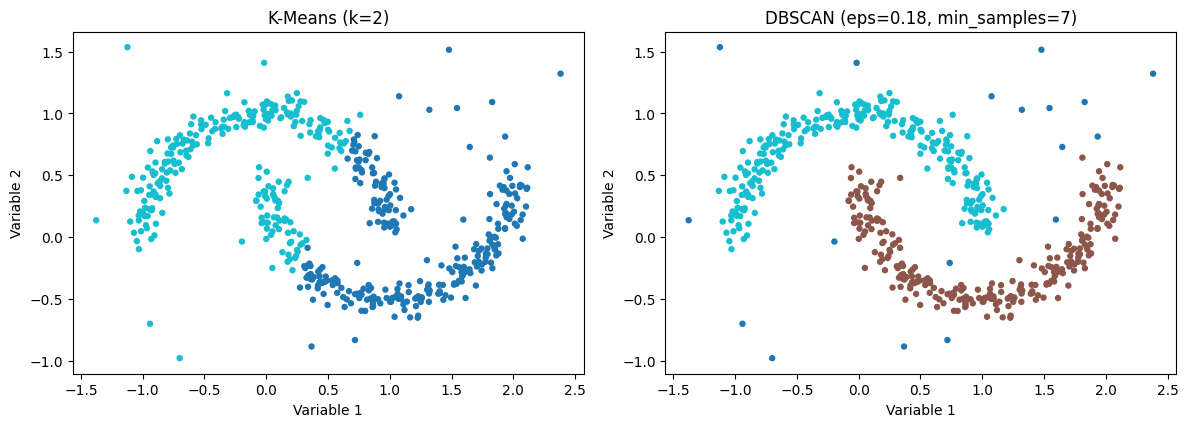

DBSCAN: 2 clusters y 18 puntos de ruido (3.4%).


In [16]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, KMeans

rng = np.random.default_rng(42)
X_lunas, _ = make_moons(n_samples=500, noise=0.07, random_state=42)
X_ruido = rng.uniform(low=[-1.5, -1.0], high=[2.5, 1.6], size=(35, 2))
X_db = np.vstack([X_lunas, X_ruido])

kmeans_lunas = KMeans(n_clusters=2, n_init=10, random_state=42)
etiquetas_kmeans = kmeans_lunas.fit_predict(X_db)

dbscan_lunas = DBSCAN(eps=0.18, min_samples=7)
etiquetas_dbscan = dbscan_lunas.fit_predict(X_db)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, etiquetas, titulo in zip(
    axes,
    [etiquetas_kmeans, etiquetas_dbscan],
    ['K-Means (k=2)', 'DBSCAN (eps=0.18, min_samples=7)']
):
    ax.scatter(X_db[:, 0], X_db[:, 1], c=etiquetas, cmap='tab10', s=13)
    ax.set_title(titulo)
    ax.set_xlabel('Variable 1')
    ax.set_ylabel('Variable 2')
    ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

n_clusters = len(set(etiquetas_dbscan) - {-1})
n_ruido = np.sum(etiquetas_dbscan == -1)
print(f'DBSCAN: {n_clusters} clusters y {n_ruido} puntos de ruido ({n_ruido / len(X_db):.1%}).')

**Para observar:** ¿en qué regiones difiere la asignación? ¿Qué representa `-1`? El color de una etiqueta numérica no tiene un significado ordinal; por ejemplo, el cluster 0 no es "mejor" que el 1.

## 2. Sensibilidad a `eps` y `min_samples`

DBSCAN no calcula automáticamente el valor adecuado de `eps`. Si es demasiado pequeño, muchos puntos pueden quedar como ruido; si es demasiado grande, grupos diferentes pueden fusionarse. Cambiar `min_samples` también cambia qué se considera una región suficientemente densa. Probemos varias configuraciones con **los mismos datos**, para que la comparación tenga sentido.

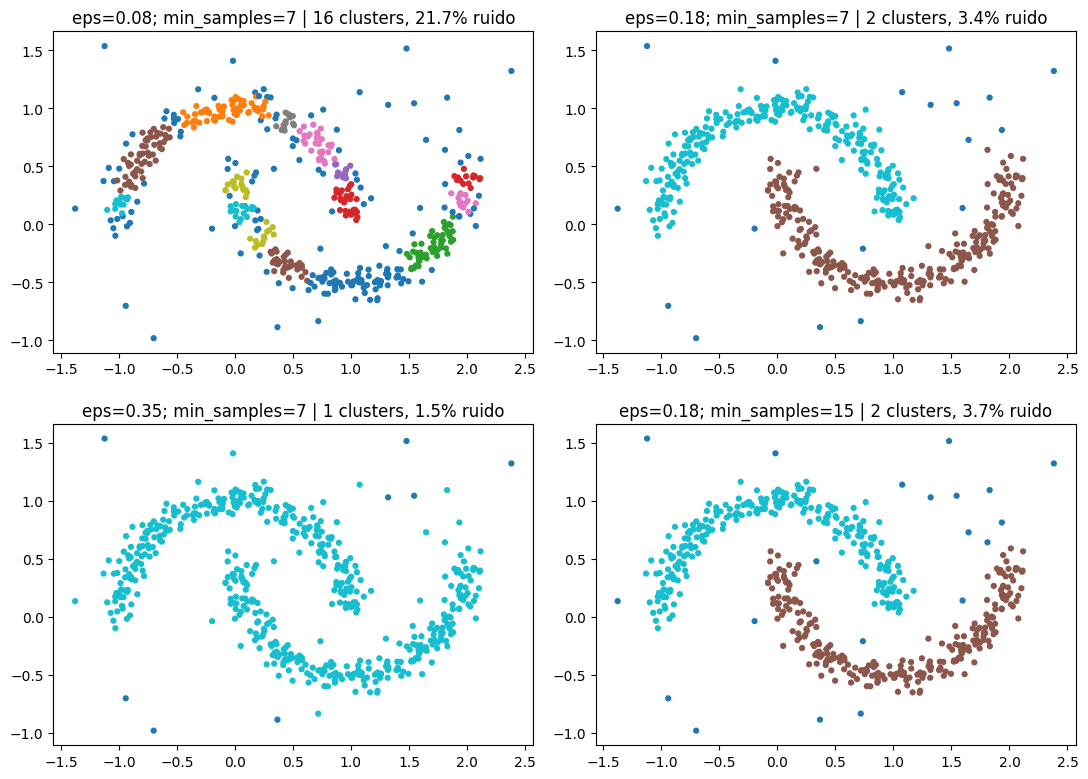

In [18]:
configuraciones = [
    (0.08, 7),
    (0.18, 7),
    (0.35, 7),
    (0.18, 15),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (eps, minimo) in zip(axes.ravel(), configuraciones):
    etiquetas = DBSCAN(eps=eps, min_samples=minimo).fit_predict(X_db)
    n_grupos = len(set(etiquetas) - {-1})
    fraccion_ruido = np.mean(etiquetas == -1)
    ax.scatter(X_db[:, 0], X_db[:, 1], c=etiquetas, cmap='tab10', s=12)
    ax.set_title(f'eps={eps}; min_samples={minimo} | {n_grupos} clusters, {fraccion_ruido:.1%} ruido')
    ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

**Preguntas:** ¿Cuál configuración separa mejor las dos lunas? ¿En cuál quedan más puntos como ruido? ¿Cuál fusiona regiones que parecen distintas? ¿Cómo afecta un cambio en la escala de las variables a la interpretación de `eps`?

No existe una configuración universal: depende de **la pregunta**, la escala de las distancias, la densidad y la forma de los datos. DBSCAN puede tener dificultades cuando existen grupos con densidades muy diferentes.

## 3. EJEMPLO: DBSCAN CON COORDENADAS GEOGRÁFICAS

Supongamos que tenemos reportes de emergencias del C5 y
queremos identificar zonas donde se concentran los reportes.

A diferencia de K-Means, DBSCAN no requiere especificar
cuántos clusters queremos encontrar.

En cambio, utiliza dos hiperparámetros:

- eps: distancia máxima para considerar que dos puntos
  son vecinos.

- min_samples: número mínimo de puntos en la vecindad
  (incluyendo al propio punto) para que sea un punto central.

DBSCAN puede clasificar las observaciones como:

1. Puntos centrales: tienen suficientes vecinos.
2. Puntos frontera: pertenecen a un cluster, pero no
   tienen suficientes vecinos para ser puntos centrales.
3. Ruido: puntos que no pertenecen a ningún cluster.

IMPORTANTE:
Estos son datos sintéticos. No representan reportes reales.

In [19]:
# ------------------------------------------------------------
# 1. Generación de coordenadas sintéticas
# ------------------------------------------------------------

# Simulamos dos concentraciones de reportes en CDMX:
#
# - Grupo 1: alrededor del Centro Histórico.
# - Grupo 2: alrededor de una zona al sur del centro.
#
# Agregamos también algunos puntos aislados para observar
# cómo DBSCAN identifica observaciones que no pertenecen
# a ninguna concentración.

centros = np.array([
    [19.4326, -99.1332],  # Centro Histórico
    [19.3600, -99.1700]   # Zona al sur
])

# Semilla para que los resultados sean reproducibles.
rng_geo = np.random.default_rng(2026)

# Generamos 70 observaciones alrededor del primer centro.
# scale controla la dispersión de las coordenadas en grados.
puntos_centro = centros[0] + rng_geo.normal(
    scale=[0.003, 0.003],
    size=(70, 2)
)

# Generamos 55 observaciones alrededor del segundo centro.
# Este grupo tiene una dispersión ligeramente mayor.
puntos_sur = centros[1] + rng_geo.normal(
    scale=[0.005, 0.005],
    size=(55, 2)
)

# Simulamos tres reportes alejados de los grupos principales.
puntos_aislados = np.array([
    [19.50, -99.25],
    [19.25, -99.05],
    [19.41, -99.30]
])

# Unimos todas las observaciones en una sola matriz.
# Cada fila representa un reporte.
# Columna 0: latitud
# Columna 1: longitud

coordenadas = np.vstack([
    puntos_centro,
    puntos_sur,
    puntos_aislados
])

print(f"Total de reportes simulados: {len(coordenadas)}")


Total de reportes simulados: 128



2. Preparación de las coordenadas


PROBLEMA:
Latitud y longitud están expresadas en grados.
#
No es adecuado interpretar directamente la distancia
euclidiana entre grados como si fueran kilómetros.
#
Para calcular distancias entre coordenadas geográficas
utilizaremos la distancia haversine, que aproxima la
distancia sobre la superficie terrestre.
#
En scikit-learn, metric="haversine" requiere que las
coordenadas estén expresadas en RADIANES, no en grados.
#
Además, eps también debe proporcionarse en radianes.

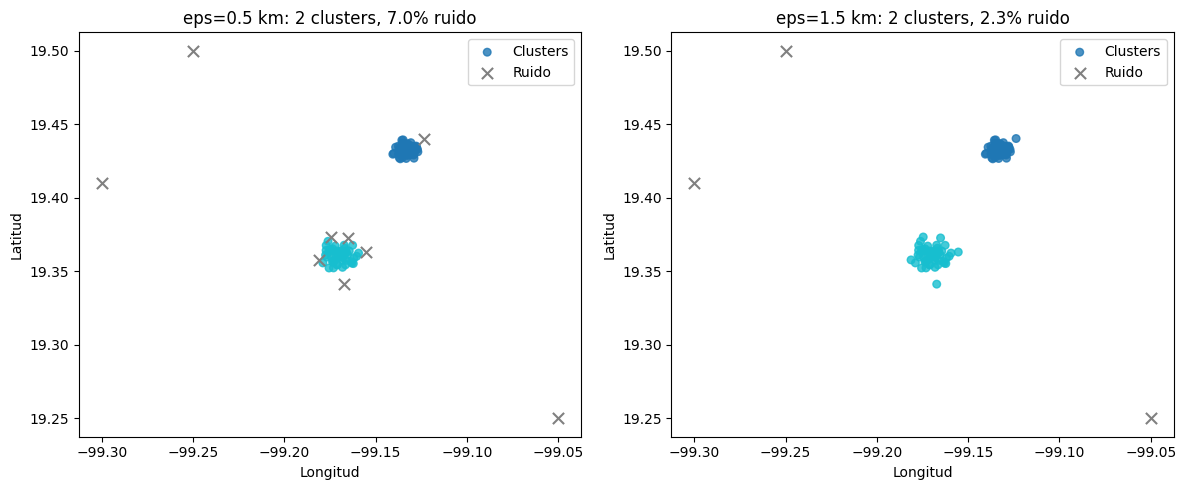

In [21]:


coordenadas_rad = np.radians(coordenadas)

# Radio medio aproximado de la Tierra en kilómetros.
radio_tierra_km = 6371.0088


# ------------------------------------------------------------
# 3. Función para implementar DBSCAN geográfico
# ------------------------------------------------------------

def dbscan_geo(coordenadas_radianes, eps_km, min_samples=5):
    """
    Aplica DBSCAN utilizando distancia haversine.

    Parámetros
    ----------
    coordenadas_radianes:
        Matriz de coordenadas [latitud, longitud] en radianes.

    eps_km:
        Radio máximo de vecindad expresado en kilómetros.

    min_samples:
        Número mínimo de observaciones en una vecindad
        para identificar un punto central.

    Retorna
    -------
    etiquetas:
        Cluster asignado a cada observación.

        0, 1, 2, ... : identificadores de clusters.
        -1           : observaciones clasificadas como ruido.
    """

    # Convertimos la distancia de kilómetros a radianes.
    # Ejemplo: 1 km / 6371.0088 km ≈ 0.000157 radianes.

    eps_rad = eps_km / radio_tierra_km

    modelo = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    # fit_predict ajusta DBSCAN y devuelve directamente
    # el cluster asignado a cada observación.
    etiquetas = modelo.fit_predict(coordenadas_radianes)

    return etiquetas


# ------------------------------------------------------------
# 4. Comparación de diferentes valores de eps
# ------------------------------------------------------------

# Queremos responder:
#
# ¿Qué ocurre cuando cambiamos la distancia máxima
# utilizada para identificar vecinos?
#
# Mantendremos min_samples=5 y compararemos:
#
# - eps = 0.5 km: vecindad relativamente pequeña.
# - eps = 1.5 km: vecindad más amplia.
#
# Esperamos que al aumentar eps:
#
# - Más puntos puedan tener suficientes vecinos.
# - Algunos puntos clasificados como ruido se incorporen
#   a clusters.
# - Algunos clusters puedan fusionarse.
#
# IMPORTANTE:
# Aumentar eps no necesariamente aumenta el número
# de clusters. Incluso puede disminuirlo.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, radio_km in zip(axes, [0.5, 1.5]):

    # Ejecutamos DBSCAN para el radio seleccionado.
    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=radio_km,
        min_samples=5
    )

    # Contamos los clusters identificados.
    # El valor -1 representa ruido, no un cluster.
    grupos = len(set(etiquetas) - {-1})

    # Calculamos la proporción de observaciones que
    # DBSCAN clasificó como ruido.
    ruido = np.mean(etiquetas == -1)

    # Visualización:
    # x = longitud
    # y = latitud
    #
    # Cada color representa una etiqueta de cluster.
    # Los puntos clasificados como ruido se dibujan
    # explícitamente en gris y con una X.

    mascara_ruido = etiquetas == -1

    ax.scatter(
        coordenadas[~mascara_ruido, 1],
        coordenadas[~mascara_ruido, 0],
        c=etiquetas[~mascara_ruido],
        cmap="tab10",
        s=30,
        alpha=0.8,
        label="Clusters"
    )

    ax.scatter(
        coordenadas[mascara_ruido, 1],
        coordenadas[mascara_ruido, 0],
        color="gray",
        marker="x",
        s=65,
        label="Ruido"
    )

    ax.set_title(
        f"eps={radio_km} km: {grupos} clusters, "
        f"{ruido:.1%} ruido"
    )

    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.legend()

plt.tight_layout()
plt.show()

### Interpretación de los resultados

En los gráficos anteriores, cada punto representa un reporte
simulado y los colores identifican los clusters encontrados
por DBSCAN.

Los puntos marcados con una **X gris** representan
observaciones clasificadas como ruido (`-1`).

**Preguntas:**

1. ¿Cuántos clusters identifica DBSCAN cuando `eps=0.5 km`?
   ¿Cuántos cuando `eps=1.5 km`?

2. ¿Por qué disminuye el porcentaje de ruido cuando
   aumentamos `eps`?

3. ¿Qué pasaría si aumentáramos `eps` a 10 km?
   ¿Seguiríamos identificando dos clusters independientes?

4. ¿Qué ocurre si mantenemos `eps=0.5 km`, pero aumentamos
   `min_samples` de 5 a 15?

5. Si estos puntos representaran llamadas reales al C5,
   ¿podríamos concluir que los clusters identificados
   representan zonas con mayor riesgo de falsas alarmas?
   ¿Qué información adicional necesitaríamos?

**Consideraciones importantes:**

- DBSCAN identifica concentraciones de observaciones,
  no necesariamente zonas de alto riesgo.
- Un cluster con muchos reportes puede reflejar una
  mayor población o una mayor frecuencia de llamadas.
- La clasificación como ruido no significa que una
  observación sea incorrecta o irrelevante.
- Los resultados dependen de los hiperparámetros y
  de la escala espacial utilizada.
- DBSCAN no utiliza una etiqueta de resultado para formar
  los clusters: su objetivo es identificar estructuras
  en las características de las observaciones.